# Módulo 3 — Diferenciação e raízes unitárias

## Seção 1 — Operador de atraso e diferenciação simples e repetida

**Estado editorial:** versão inicial completa para revisão. **Integração:** teoria, demonstrações, exemplos resolvidos e Python no mesmo documento. **Pré-requisitos:** processos estocásticos e estacionariedade (Módulo 1); tendência determinística e estocástica (Módulo 2); somatórios e polinômios.

**Fontes conferidas:** Morettin e Toloi, *Análise de Séries Temporais: modelos lineares univariados*, v. 1, 3ª ed., §1.4, p. 6, equações (1.2)–(1.5), e §5.3.1, p. 143, especialmente (5.72) e o exemplo de tendência determinística. Para a sequência das aulas, mapeamento do curso, aulas “Aula 4 — ACF, CCF, Diferenciação e Retornos” e “Aplicação de Diferenças”. As deduções detalhadas, o exemplo numérico, os exercícios e os códigos abaixo são **complementações didáticas elaboradas para este livro**. Não se atribuem esses exemplos ao texto dos autores.

### Objetivos de aprendizagem

Ao final desta seção, você deverá ser capaz de: (i) distinguir deslocamento temporal e diferenciação; (ii) representar esses operadores algebricamente; (iii) deduzir diferenças de ordem dois e três; (iv) calcular diferenças manualmente e com NumPy; (v) comparar a diferenciação de uma tendência determinística com a de um passeio aleatório; (vi) explicar por que uma série diferenciada não é automaticamente estacionária e por que diferenciar demais pode ser prejudicial.

### 1. Motivação: por que comparar observações consecutivas?

Uma série observada pode ter média que muda com o tempo. Tomemos o modelo já estudado:

$$
Z_t=\alpha+\beta t+\varepsilon_t,
$$

em que $\varepsilon_t$ tem média zero e variância finita $\sigma^2$. A diferença entre observações consecutivas elimina o nível fixo $\alpha$ e a parte linear crescente $\beta t$:

$$
\begin{aligned}
Z_t-Z_{t-1}
&=(\alpha+\beta t+\varepsilon_t)
 -(\alpha+\beta(t-1)+\varepsilon_{t-1})\\
&=\beta+\varepsilon_t-\varepsilon_{t-1}.
\end{aligned}
$$

Isso **não** equivale a recuperar diretamente os erros originais $\varepsilon_t$. O novo erro envolve dois instantes: $\varepsilon_t-\varepsilon_{t-1}$. A consequência estatística será importante.

**Ideia central:** diferenciar transforma a sequência de níveis em uma sequência de **variações**, mas a interpretação dessas variações depende do mecanismo probabilístico gerador.

### 2. Operador de atraso $B$: definição e convenções

Para um processo indexado pelos inteiros, define-se o operador de atraso (*backshift*) $B$ por:

$$
BZ_t=Z_{t-1}.
$$

O lado esquerdo é um operador aplicado à família $\{Z_t\}$; não significa multiplicação usual entre números. Aplicando-o novamente:

$$
B^2Z_t=B(BZ_t)=BZ_{t-1}=Z_{t-2}.
$$

Por indução, para $k\geq 0$:

$$
B^kZ_t=Z_{t-k}.
$$

**Exemplo:** se $z_1=10$, $z_2=13$ e $z_3=19$, então $Bz_3=z_2=13$ e $B^2z_3=z_1=10$.

Para uma série observada apenas em $t=1,\ldots,N$, os atrasos não têm valores disponíveis nos primeiros instantes sem informação anterior. Em códigos, não devemos preencher silenciosamente essa falta com zeros: isso alteraria a interpretação matemática.

**Linearidade do operador.** Para sequências $X_t,Y_t$ e constantes $a,b$:

$$
B(aX_t+bY_t)=aX_{t-1}+bY_{t-1}=aBX_t+bBY_t.
$$

Essa propriedade permite trabalhar com polinômios em $B$.

### 3. Primeira diferença: definição e dedução

O operador de primeira diferença é:

$$
\boxed{\Delta=1-B}
$$

Portanto:

$$
\boxed{\Delta Z_t=(1-B)Z_t=Z_t-Z_{t-1}.}
$$

Aqui, $1$ representa o operador identidade: $1\,Z_t=Z_t$.

**Interpretação das unidades:** se $Z_t$ representa precipitação mensal em milímetros, $\Delta Z_t$ é a diferença, em milímetros, entre os totais de dois meses; não é a precipitação diária nem uma taxa percentual. Se os instantes tiverem espaçamento $\delta$ em unidades de tempo, a diferença dividida por $\delta$ aproxima uma taxa de variação: $(Z_t-Z_{t-1})/\delta$.

#### 3.1 Exemplo manual

Considere a sequência observada:

$$
(z_1,z_2,z_3,z_4,z_5)=(3,5,8,12,17).
$$

Calculando:

| Instante | $z_t$ | $\Delta z_t=z_t-z_{t-1}$ |
|---|---:|---:|
| 1 | 3 | não disponível |
| 2 | 5 | $5-3=2$ |
| 3 | 8 | $8-5=3$ |
| 4 | 12 | $12-8=4$ |
| 5 | 17 | $17-12=5$ |

Logo, a série de diferenças válidas é $(2,3,4,5)$. Ela tem **quatro valores**, e não cinco. O primeiro valor original não possui antecessor no trecho observado.

### 4. Diferenças repetidas: segunda ordem e além

A segunda diferença aplica $\Delta$ duas vezes:

$$
\Delta^2 Z_t=\Delta(\Delta Z_t).
$$

Escrevendo explicitamente:

$$
\begin{aligned}
\Delta^2 Z_t
&=(Z_t-Z_{t-1})-(Z_{t-1}-Z_{t-2})\\
&=\boxed{Z_t-2Z_{t-1}+Z_{t-2}}.
\end{aligned}
$$

A mesma expressão decorre da identidade algébrica:

$$
(1-B)^2=1-2B+B^2.
$$

No exemplo anterior, a primeira diferença é $(2,3,4,5)$; a segunda será $(3-2,4-3,5-4)=(1,1,1)$.

Pelo binômio de Newton, a diferença de ordem inteira $d\geq0$ é:

$$
\boxed{\Delta^dZ_t=(1-B)^dZ_t=\sum_{k=0}^{d}(-1)^k\binom{d}{k}Z_{t-k}.}
$$

Para $d=3$:

$$
\Delta^3Z_t=Z_t-3Z_{t-1}+3Z_{t-2}-Z_{t-3}.
$$

**Demonstração sobre tendências polinomiais.** Para $p(t)=at^m+\cdots$, a diferença $p(t)-p(t-1)$ tem grau no máximo $m-1$, pois os termos de grau $m$ se cancelam. Repetindo $m$ vezes obtém-se uma constante; após $m+1$ diferenças, obtém-se zero. Por exemplo:

$$
\Delta(t^2)=t^2-(t-1)^2=2t-1,
$$

$$
\Delta^2(t^2)=(2t-1)-(2(t-1)-1)=2,
$$

$$
\Delta^3(t^2)=0.
$$

**Limite da interpretação:** essa propriedade é algébrica e diz respeito ao componente polinomial; não prova que a série com ruído ficará estacionária depois da diferenciação.

### 5. Duas estruturas diferentes de tendência

#### 5.1 Modelo com tendência determinística

Seja $Z_t=\alpha+\beta t+\varepsilon_t$, com $\varepsilon_t$ ruído branco de média zero, variância $\sigma^2>0$ e covariância nula entre instantes distintos. Como já calculamos:

$$
\Delta Z_t=\beta+\varepsilon_t-\varepsilon_{t-1}.
$$

A esperança da série diferenciada é:

$$
E[\Delta Z_t]=\beta.
$$

Para obter a variância, usamos $\mathrm{Cov}(\varepsilon_t,\varepsilon_{t-1})=0$:

$$
\begin{aligned}
\mathrm{Var}(\Delta Z_t)
&=\mathrm{Var}(\varepsilon_t-\varepsilon_{t-1})\\
&=\sigma^2+\sigma^2-2\cdot0=2\sigma^2.
\end{aligned}
$$

A covariância na defasagem 1 é:

$$
\begin{aligned}
\mathrm{Cov}(\Delta Z_t,\Delta Z_{t-1})
&=\mathrm{Cov}(\varepsilon_t-\varepsilon_{t-1},\varepsilon_{t-1}-\varepsilon_{t-2})\\
&=-\mathrm{Var}(\varepsilon_{t-1})=-\sigma^2.
\end{aligned}
$$

Para $|h|>1$, não há inovações compartilhadas, então a covariância é zero. Em resumo:

$$
\gamma_{\Delta Z}(h)=
\begin{cases}
2\sigma^2,&h=0,\\
-\sigma^2,&|h|=1,\\
0,&|h|>1.
\end{cases}
$$

Este processo diferenciado **é fracamente estacionário** sob as hipóteses dadas, mas possui correlação de primeira defasagem $-1/2$. Diferenciar criou uma dependência entre observações adjacentes, mesmo quando as inovações originais não eram correlacionadas.

**Observação metodológica:** remover diretamente a tendência determinística conhecida produz $Z_t-(\alpha+\beta t)=\varepsilon_t$, que não é a mesma série obtida por diferenciação. Quando os parâmetros são desconhecidos, podemos estimar a tendência a partir dos dados, mas isso acrescenta incerteza de estimação.

#### 5.2 Passeio aleatório com deriva

Considere $W_0=\alpha$ e:

$$
W_t=W_{t-1}+\beta+\varepsilon_t,
$$

com inovações não correlacionadas, de média zero e variância constante. Subtraindo $W_{t-1}$:

$$
\boxed{\Delta W_t=\beta+\varepsilon_t.}
$$

Portanto, a primeira diferença apresenta média $\beta$, variância $\sigma^2$ e autocovariância zero para defasagens não nulas. O passeio aleatório em nível não é fracamente estacionário quando $\sigma^2>0$, pois sua variância cresce como $t\sigma^2$ se o valor inicial for fixo.

**Comparação:** ambos podem ter a mesma função média em nível, mas suas séries diferenciadas exibem estruturas probabilísticas distintas. É inadequado considerar “tendência removida” sinônimo de “mesmo processo residual”.

### 6. Python integrado: do cálculo manual à visualização

**Ambiente:** Python 3.10 ou superior; bibliotecas NumPy e Matplotlib. O exemplo foi executado com verificações numéricas. Não utiliza dados reais.

`np.array()` cria um vetor numérico; fatias `z[1:]` e `z[:-1]` selecionam os elementos a partir do segundo e até o penúltimo, respectivamente; `np.diff(z)` calcula diferenças adjacentes. Para a simulação, `np.random.default_rng(semente)` controla o gerador pseudoaleatório e `np.cumsum()` calcula somas acumuladas. O primeiro elemento do passeio é fixado em 10; por isso, acumulamos somente `eps[1:]`, correspondentes aos incrementos entre os instantes 0 e 1 em diante.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Nível 1: cálculo explícito
z = np.array([3., 5., 8., 12., 17.])
d1 = z[1:] - z[:-1]
d2 = d1[1:] - d1[:-1]
print("Primeira diferença:", d1)
print("Segunda diferença:", d2)

# Nível 2: conferência com uma função pronta
assert np.allclose(d1, np.diff(z))
assert np.allclose(d2, np.diff(z, n=2))

# Nível 3: dois processos que possuem a mesma média teórica
rng = np.random.default_rng(2026)
n = 240
t = np.arange(n)
beta = 0.12
eps = rng.normal(loc=0, scale=1.0, size=n)
trend = 10 + beta*t + eps
random_walk = 10 + beta*t + np.concatenate(([0.0], np.cumsum(eps[1:])))

d_trend = np.diff(trend)
d_walk = np.diff(random_walk)

fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex="col")
axs[0, 0].plot(t, trend)
axs[0, 0].plot(t, 10 + beta*t, "--")
axs[0, 0].set_title("Tendência determinística")
axs[0, 1].plot(t, random_walk)
axs[0, 1].plot(t, 10 + beta*t, "--")
axs[0, 1].set_title("Passeio aleatório com deriva")
axs[1, 0].plot(t[1:], d_trend)
axs[1, 0].set_title("Diferença: β + εₜ − εₜ₋₁")
axs[1, 1].plot(t[1:], d_walk)
axs[1, 1].set_title("Diferença: β + εₜ")
for row in axs:
    for ax in row:
        ax.grid(alpha=0.3)
        ax.set_ylabel("Valor")
for ax in axs[1]:
    ax.set_xlabel("Tempo (índice)")
plt.tight_layout()
plt.show()


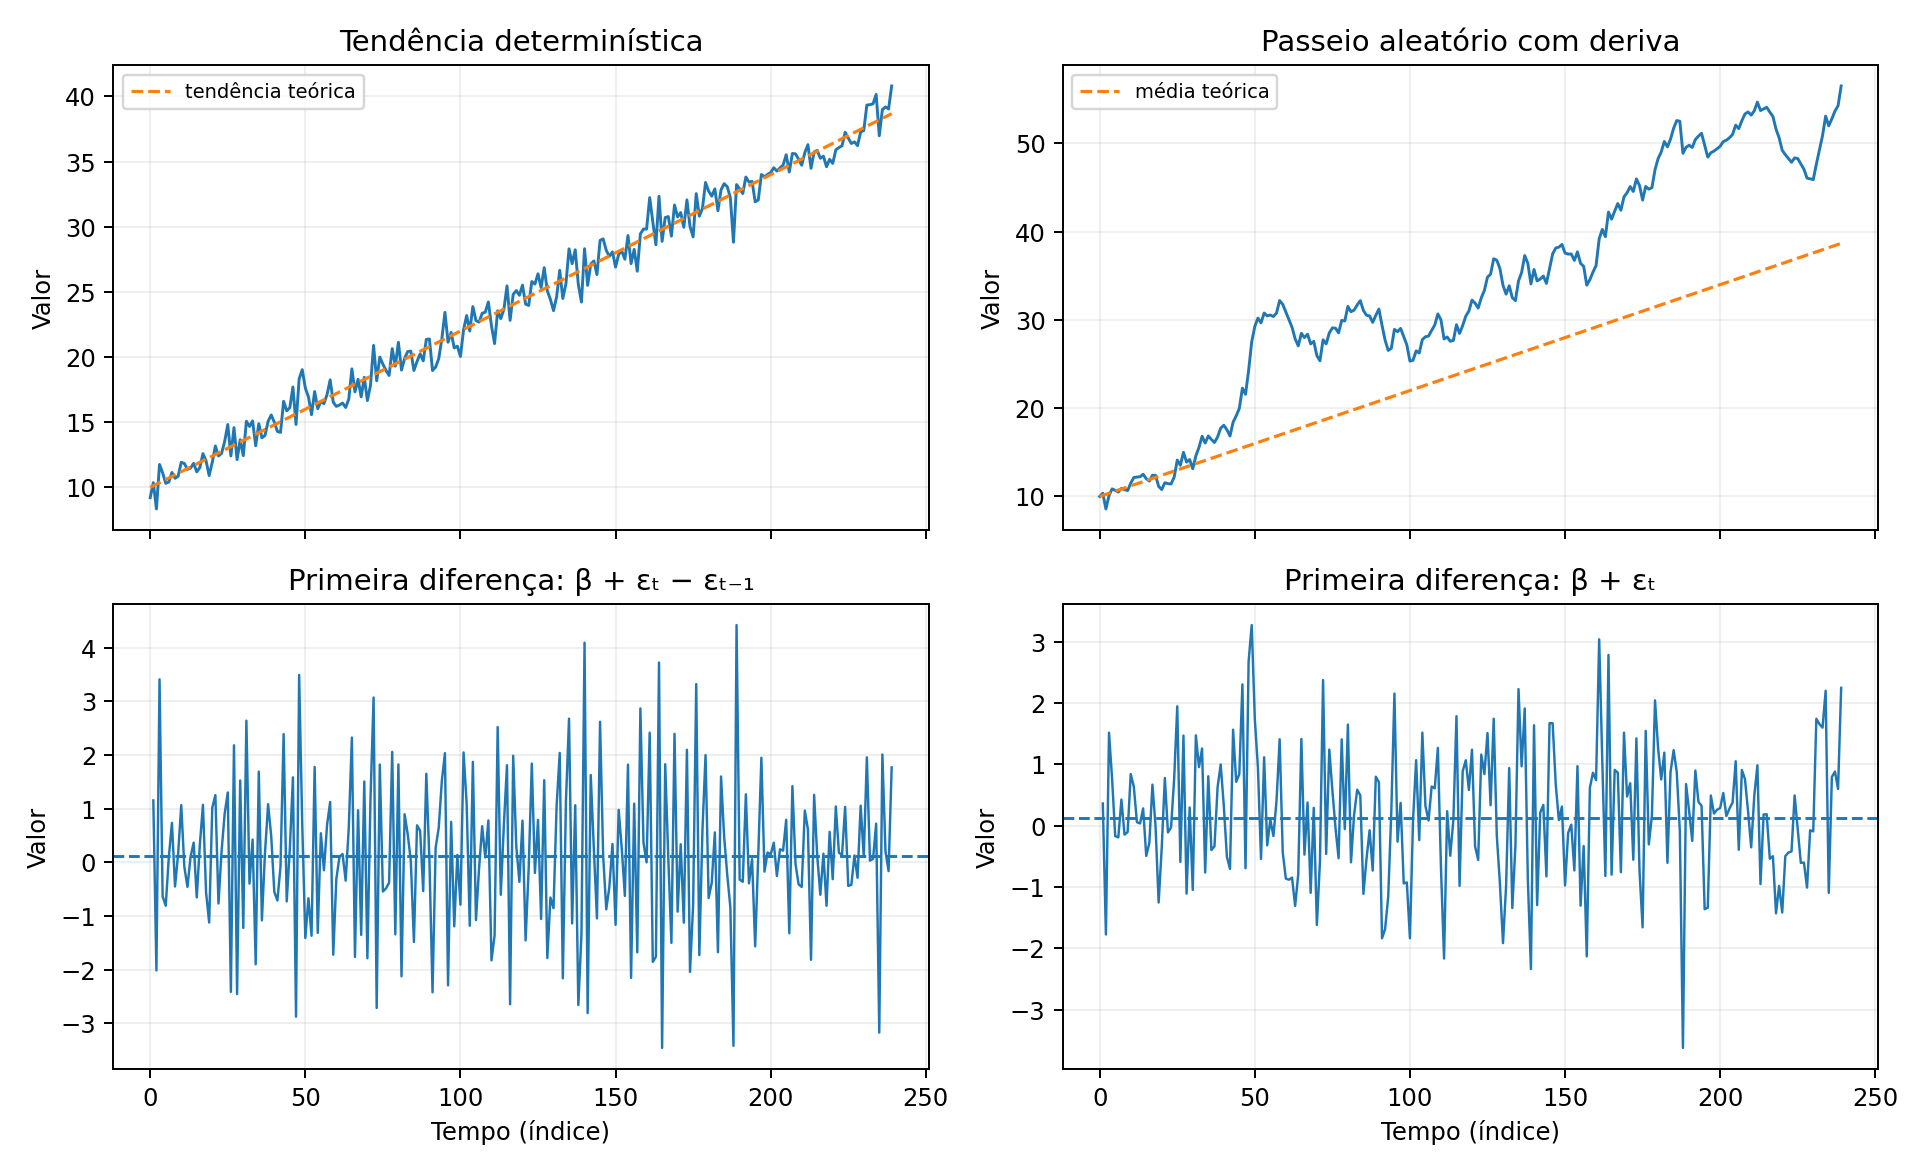

*Figura 1 — Experimento sintético: uma tendência determinística e um passeio aleatório com deriva, usando as mesmas inovações para favorecer a comparação. As linhas tracejadas indicam a mesma função média teórica. Após a diferenciação, os mecanismos diferem. Uma realização visual não demonstra estacionariedade.*

#### 6.1 O que os resultados permitem afirmar?

A identidade `np.diff(trend)` coincide, elemento a elemento, com $\beta+\varepsilon_t-\varepsilon_{t-1}$, enquanto `np.diff(random_walk)` coincide com $\beta+\varepsilon_t$ para os instantes a partir do segundo valor armazenado. Isso é uma **verificação algébrica computacional**, não um teste estatístico. Em séries reais, a decomposição em tendência e erro não é diretamente observável, por isso a interpretação depende das hipóteses do modelo.

### 7. Diferenciar não é sempre a melhor escolha

- **Sobrediferenciação:** mesmo se um processo já for estacionário, sua diferença pode introduzir autocorrelação negativa desnecessária e complicar a modelagem.
- **Redução de observações:** cada diferença simples reduz em uma unidade o número de valores calculáveis no trecho finito.
- **Amplificação de ruído de alta frequência:** subtrair valores próximos pode enfatizar variações rápidas e erros de medida.
- **Mudança de significado:** o nível $Z_t$ e a variação $\Delta Z_t$ respondem a perguntas diferentes.
- **Falhas e espaçamento irregular:** diferenças de registros consecutivos não equivalem necessariamente à mesma duração física; é preciso verificar os intervalos de coleta.
- **Estacionariedade não garantida:** variância variável, quebras estruturais e outros mecanismos podem persistir depois de uma diferença.

### 8. Exercícios (sem solução integral)

**Conceitual.** Explique por que $\Delta Z_t$ não é o mesmo objeto estatístico que $Z_t-(\alpha+\beta t)$ no modelo com tendência determinística.

**Algébrico.** Desenvolva $(1-B)^3Z_t$ sem consultar a fórmula já apresentada; identifique os quatro coeficientes.

**Numérico.** Aplique primeira e segunda diferenças à sequência $(2,6,12,20,30,42)$. Quantos resultados permanecem depois de cada operação?

**Demonstração.** Mostre que a diferença de $p(t)=at^2+bt+c$ é linear e que sua segunda diferença vale $2a$.

**Programação guiada.** Antes de programar, escreva um pseudocódigo para calcular $\Delta^2Z_t$ usando apenas uma lista e laços `for`. Compare sua saída com `np.diff(z, n=2)` e explique os índices.

**Pesquisa crítica.** Uma série foi diferenciada e sua média amostral parece constante. Isso demonstra estacionariedade fraca? Identifique quais condições ainda precisariam ser examinadas.

**Conferência selecionada:** no exercício de demonstração, $\Delta p(t)=a(2t-1)+b$ e $\Delta^2p(t)=2a$.

### 9. Síntese e transição

A primeira diferença é o operador $(1-B)$; a $d$-ésima diferença é $(1-B)^d$. Suas propriedades algébricas devem ser separadas das propriedades estatísticas: a transformação pode estabilizar a média de determinados modelos, mas não garante estacionariedade e pode alterar a dependência. Na próxima seção estudaremos o operador de diferença **sazonal**, que compara valores separados por um período completo.

### Referências utilizadas

- MORETTIN, Pedro A.; TOLOI, Clélia M. C. *Análise de Séries Temporais: Modelos Lineares Univariados*. Volume 1. 3. ed. São Paulo: Blucher, 2018. §1.4, p. 6; §5.3.1, p. 143. Conferência visual no arquivo acadêmico do projeto.
- *Mapeamento de conteúdos para Iniciação Científica: Séries Temporais*, registros das aulas “Aula 4 — ACF, CCF, Diferenciação e Retornos” e “Aplicação de Diferenças”, arquivo do projeto. Utilizado para organização pedagógica, não como substituto das definições do livro.

**Nota de escopo:** os testes ADF/KPSS, a teoria formal de integração e as raízes unitárias serão desenvolvidos nas próximas seções do Módulo 3, sem pressupô-los nesta etapa.